In [1]:
import sys
import os
import pickle
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib import pyplot as plt, colors as mplcolors, patches, ticker, cm

sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
file_id = 0

In [4]:
path = os.path.join(read_utils.get_data_path(), 'brain')

# read
(filename,
 traces,
 states, markers) = read_utils.get_data(path, file_id)
timestamps = read_utils.get_timestamps(read_utils.get_filepath(path, file_id))

# clear nan values
mask = markers.notna().all(axis=1)

traces = traces[mask]
markers = markers[mask]
states = states[mask]

# naive ID unknown neurons
traces.columns = pd.Index([
	f'{file_id:02d}_{n_id:03d}' if empty or type(label) is not str else label for n_id, (label, empty) in
	enumerate(zip(traces.columns, traces.columns == ''))
])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
	return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rate = read_utils.get_sampling_rate(os.path.join(path, filename))
traces = pd.DataFrame(highpass_butter(traces.values, sampling_rate, 1 / 100), columns=traces.columns)
#markers_grad = pd.DataFrame(np.gradient(markers.values, axis=0), columns=markers.columns)

/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/notebooks/exploration/../../src/utils_fly/read_utils.py:91: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  data = pickle.load(file)


In [5]:
markers_zs = pd.DataFrame(
	data=(markers.values - markers.values.mean(axis=0)) / np.where((marker_std := np.std(markers.values, axis=0)) == 0.0, 1.0, marker_std),
	columns=markers.columns)

In [14]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca([traces], scale=False,
												 n_pc=4)

traces_residual = [pd.DataFrame(t.values - t_rec.values, columns=t.columns) for t, t_rec in zip([traces], recos_manifold)][0]

In [6]:
# max_shift_seconds = 5
# max_shift = int(max_shift_seconds * sampling_rates)
#
# print('maximum max_shift_seconds', int(max_shift_seconds))
# print(f'actual max_shift_seconds: {max_shift / sampling_rates:.3f}s')
#
# if max_shift > 0:
# 	markers_shifted = dict()
# 	for marker_label in markers.columns:
# 		for s in range(1, int(max_shift) + 1):
# 			shift_seconds = s / sampling_rates
# 			markers_shifted[f'{marker_label}-{shift_seconds:.2f}s'] = np.pad(markers[marker_label].values[:-s], ((s, 0),))
# 	markers = pd.concat(
# 		[markers, pd.DataFrame(markers_shifted, index=markers.index)], axis=1)

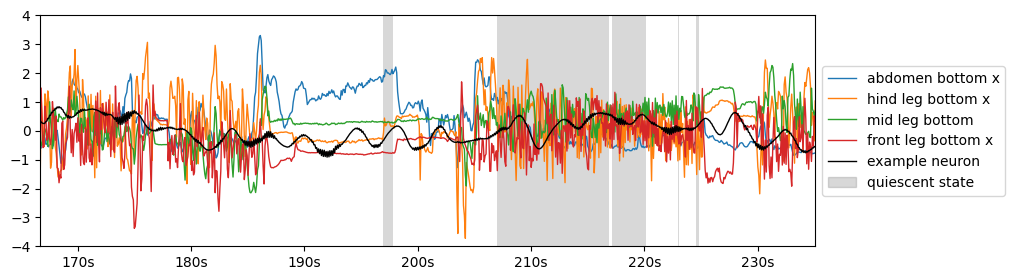

In [23]:
# Select the range you want to plot
min_x = int(140 * sampling_rate)
max_x = int(210 * sampling_rate)

# Prepare the heatmap data (example: using 'still' state)
heatmap = states['still'].values[min_x:max_x + 1].reshape(-1, 1)
heatmap = heatmap.T  # shape (1, timepoints)

# Prepare the timestamps for the selected range
timestamps_sel = timestamps[min_x:max_x + 1]

plt.figure(figsize=(10, 3))


# Plot the heatmap, aligned with timestamps
plt.imshow(
    heatmap,
    aspect='auto',
    cmap=mplcolors.LinearSegmentedColormap.from_list(
        'middle_third',
        plt.get_cmap('binary')(np.linspace(0, 1 / 2, 256))
    ),
    interpolation='nearest',
    alpha=0.3,
    extent=[timestamps_sel[0], timestamps_sel[-1], -4, 4],
)

lw = 1
# Plot your traces as before
plt.plot(timestamps_sel, markers_zs.loc[min_x:max_x, ['abdomen-bot_x']].values, label='abdomen bottom x', linewidth=lw)
plt.plot(timestamps_sel, markers_zs.loc[min_x:max_x, ['hind-bot_x']].values, label='hind leg bottom x', linewidth=lw)
plt.plot(timestamps_sel, markers_zs.loc[min_x:max_x, ['mid-bot_x']].values, label='mid leg bottom', linewidth=lw)
plt.plot(timestamps_sel, markers_zs.loc[min_x:max_x, ['fore-bot_x']].values, label='front leg bottom x', linewidth=lw)
plt.plot(timestamps_sel, traces_residual.loc[min_x:max_x, ['00_137']] * 100, label='example neuron', linewidth=1, color='black')

plt.xticks(plt.xticks()[0], [f'{int(t)}s' for t in plt.xticks()[0]])
plt.xlim(timestamps_sel[0], timestamps_sel[-1])
plt.ylim(-4, 4)
heatmap_patch = patches.Patch(color='gray', alpha=0.3, label='quiescent state')
plt.legend(
    handles=plt.gca().get_legend_handles_labels()[0] + [heatmap_patch],
    loc='center left', bbox_to_anchor=(1, 0.5)
)
plt.savefig('../../out/plots/markers_traces', dpi=300, bbox_inches='tight')
plt.show()

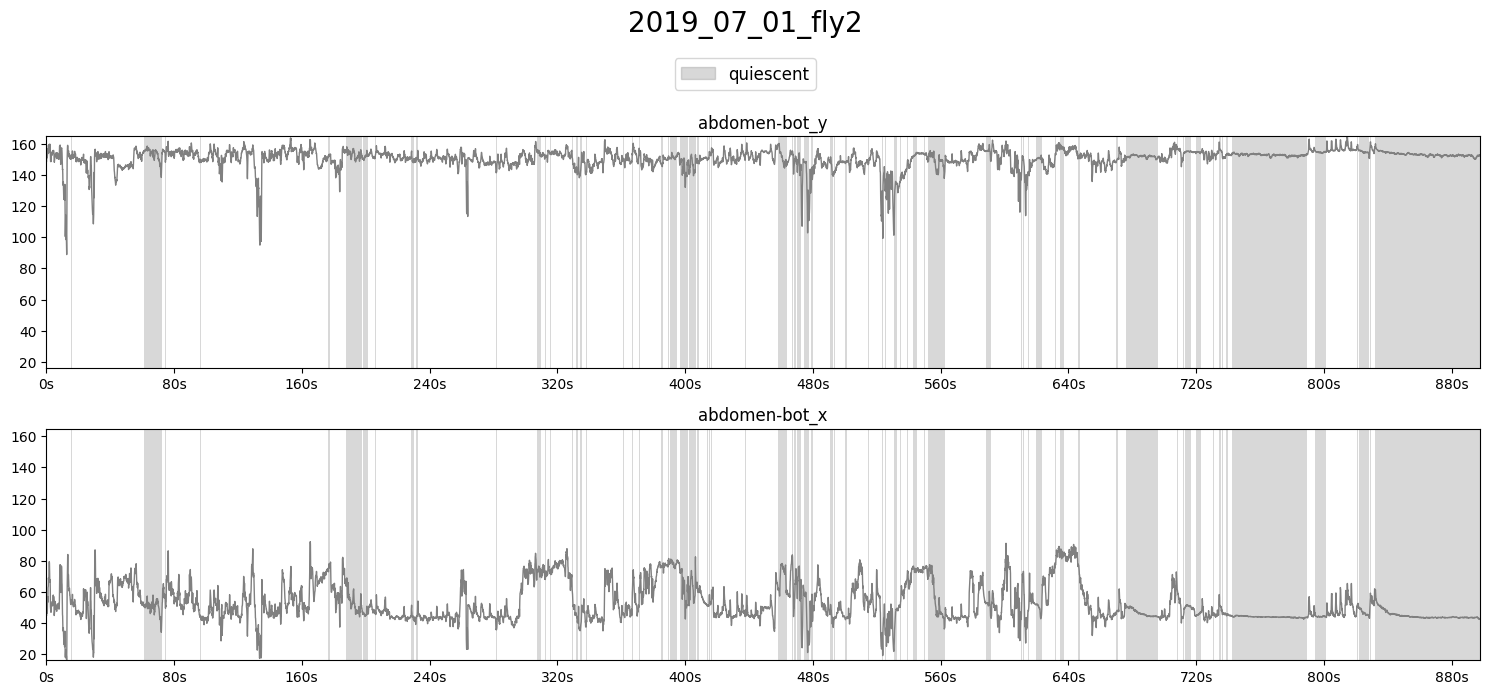

In [6]:
max_x = markers.values.shape[0]
# max_x = 1000

plot_utils.plot_traces(markers.loc[:max_x, ['abdomen-bot_y', 'abdomen-bot_x']],
					   states[['still']].loc[:max_x],
					   timestamps,
					   label='quiescent',
					   title=f'{filename}',
					   n_plots=None, plots_per_row=1, top_space=1, ylimits=None)

In [ ]:
print(traces.shape)

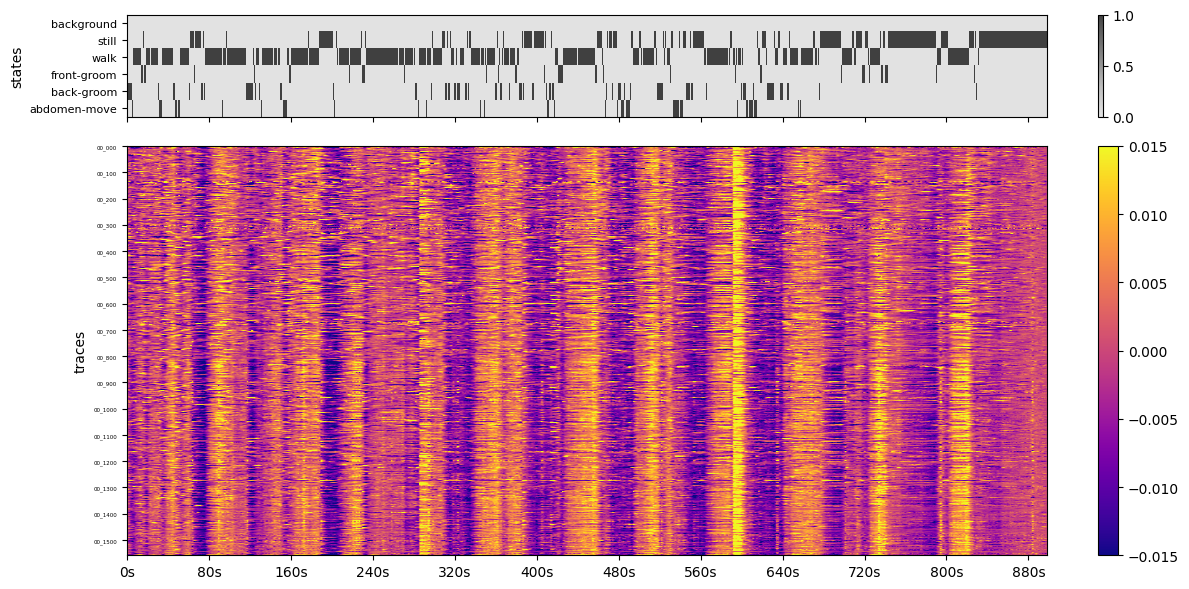

In [7]:
plot_utils.plot_heatmap_stack(
	traces, states, timestamps,
	'traces', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False)

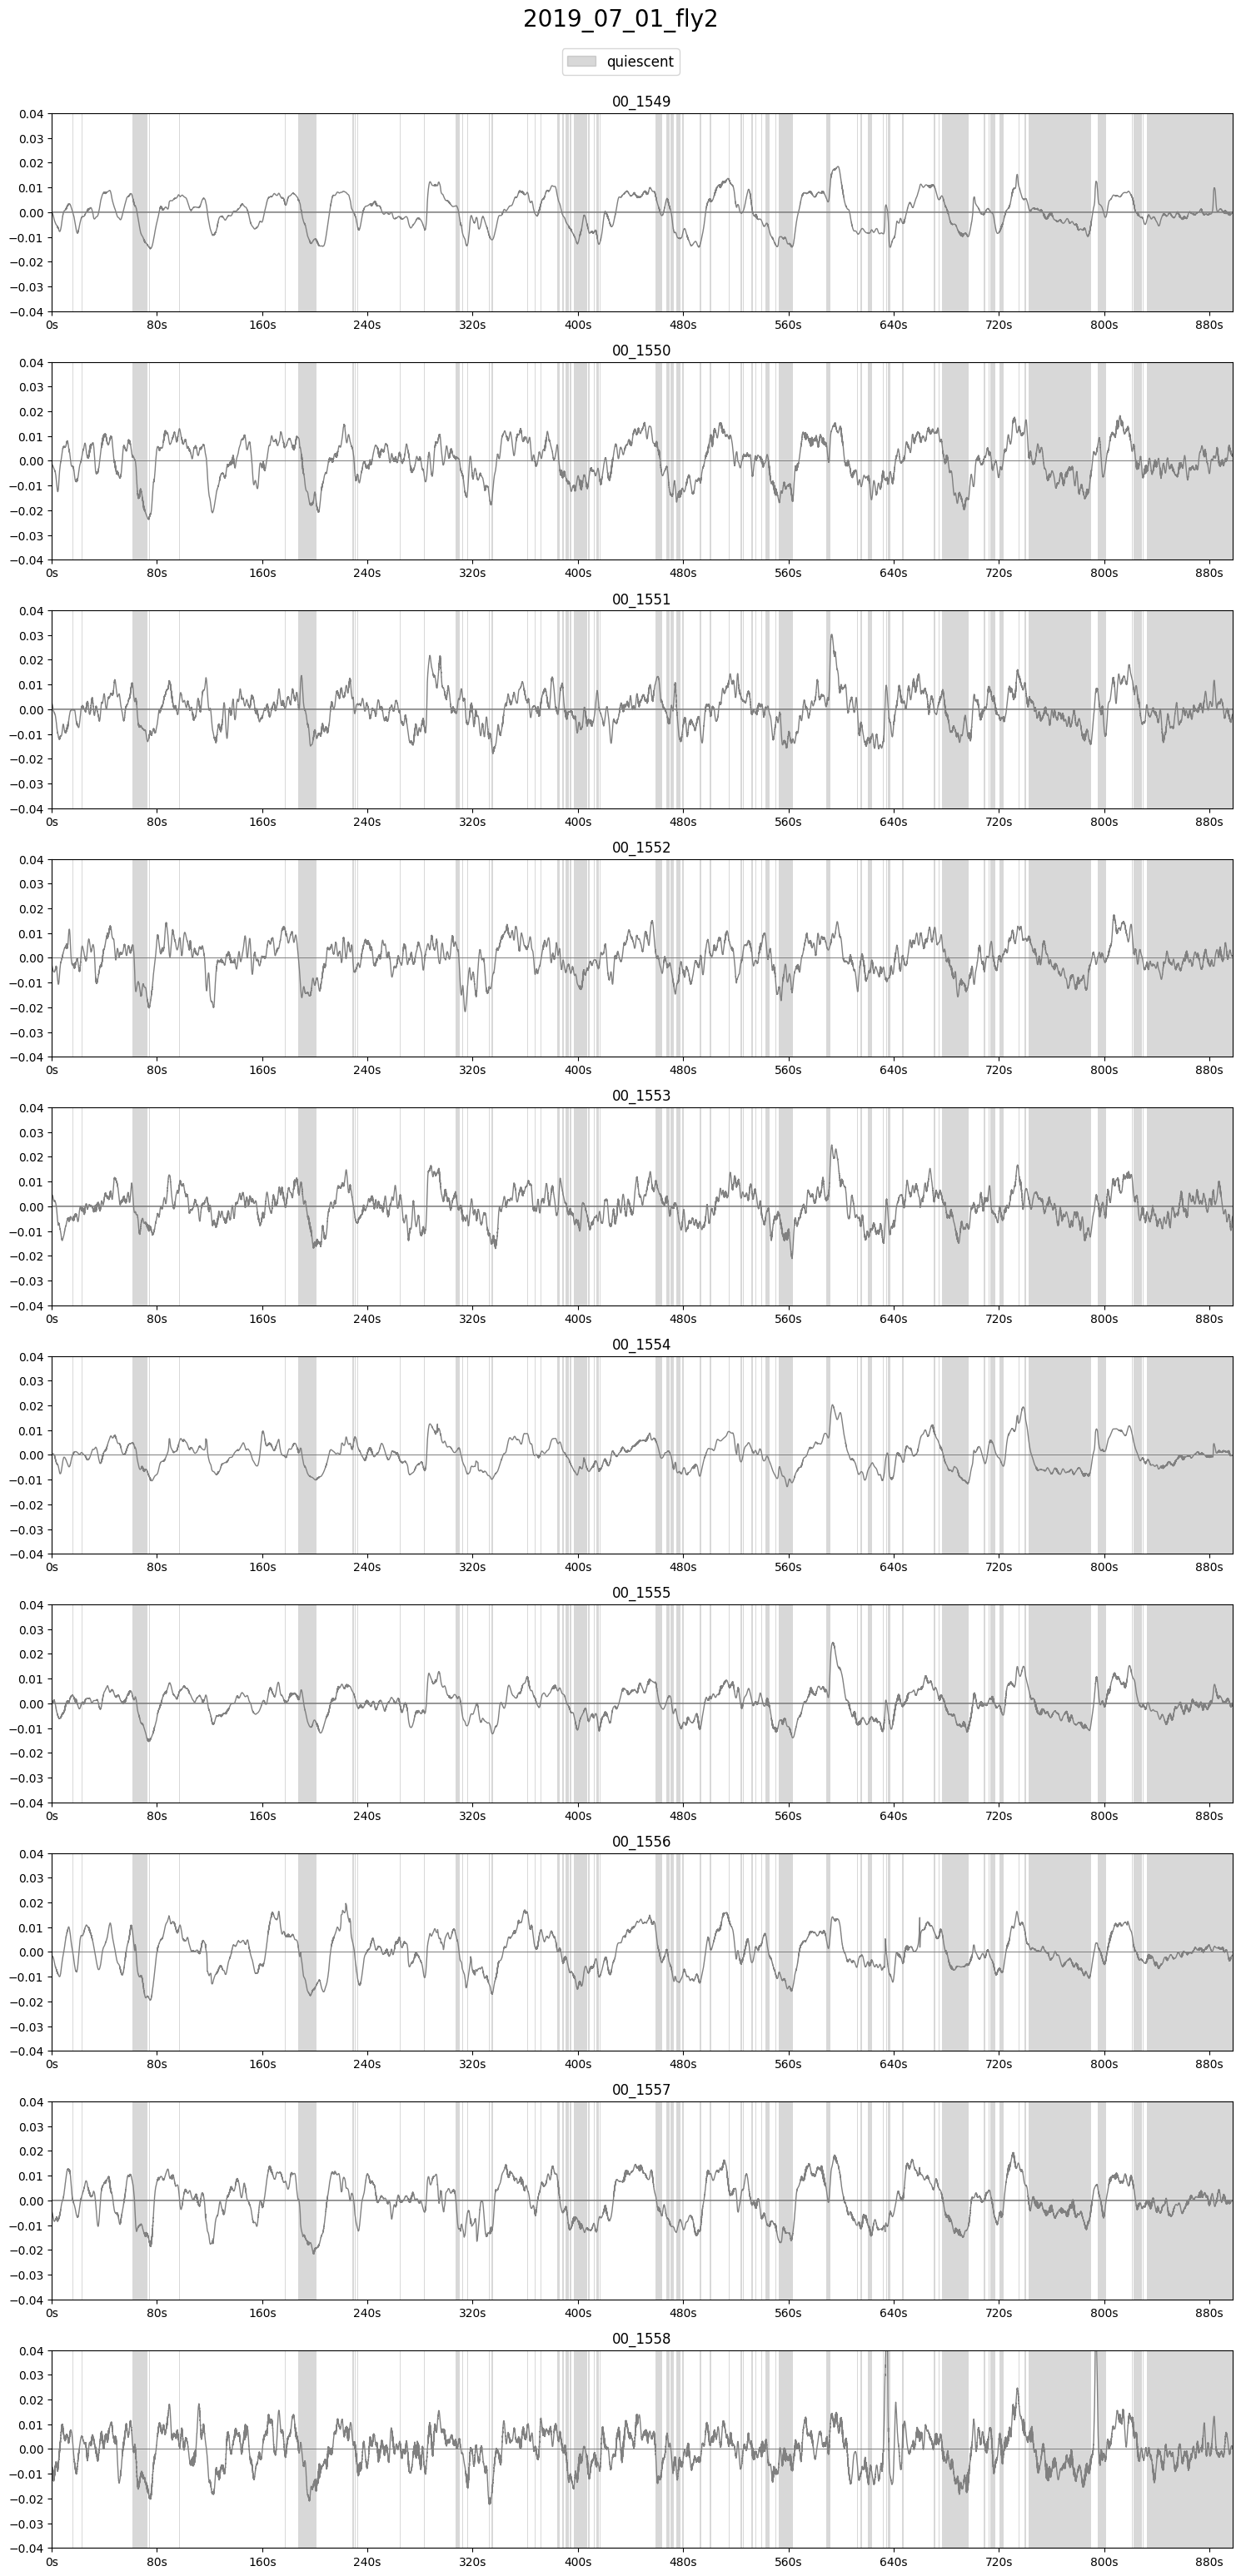

In [8]:
plot_utils.plot_traces(traces.iloc[:, -10:],
					   states['still'],
					   timestamps,
					   label='quiescent',
					   title=f'{filename}',
					   n_plots=10, plots_per_row=1, top_space=1, ylimits=(-0.04, 0.04))

In [ ]:
markers_zs = [
	pd.DataFrame(
		data=(marker.values - marker.values.mean(axis=0)) / np.where((marker_std := np.std(marker.values, axis=0)) == 0.0, 1.0, marker_std),
		columns=marker.columns)
	for marker in [markers]
][0]

# flail

In [ ]:
file_id_fl = 4

In [ ]:
path_fl = os.path.join(read_utils.get_data_path(), 'brain/incomplete/no_pickle/flailing')

(filename_fl,
 traces_fl,
 states_fl, markers_fl) = read_utils.get_data(path_fl, file_id_fl, with_markers=False)

# # clear nan values
# 	mask = markers_fl.notna().all(axis=1)
#
# 	traces_fl = traces_fl[mask]
# 	markers_fl = markers_fl[mask]
# 	states_fl = states_fl[mask]

# naive ID unknown neurons
traces_fl.columns = pd.Index([
	f'{file_id_fl:02d}_{n_id:03d}' if empty or type(label) is not str  else label for n_id, (label, empty) in enumerate(zip(traces_fl.columns, traces_fl.columns == ''))
])

# preprocess
def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = read_utils.get_sampling_rate(os.path.join(path, filename))
traces = pd.DataFrame(highpass_butter(traces.values, sampling_rates, 1 / 100), columns=traces.columns)
markers_grad = pd.DataFrame(np.gradient(markers.values, axis=0), columns=markers.columns)

In [ ]:
print(traces_fl.shape)

In [ ]:
plot_utils.plot_heatmap_stack(
	traces_fl, states_fl[['?']], timestamps,
	'traces flailing', 'states',
	zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False, height_ratios=(1, 16))

In [ ]:
plot_utils.plot_traces(traces_fl.iloc[:, -10:],
					   states_fl['?'],
					   timestamps,
					   label='?',
					   title=f'{filename_fl}',
					   n_plots=10, plots_per_row=1, top_space=1, ylimits=(-0.04, 0.04))